# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [ ]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error

#### **1.1.1**
Load the dataset

In [ ]:
# Load the data
car_df = pd.read_csv('/content/Car_Price_data.csv')
car_df.head()

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Catalytic Converter,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Sport seats,Sport suspension,Voic...","ABS,Central door lock,Central door lock with r...",2.0,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer","Alloy wheels,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport seats,Voice Control","ABS,Alarm system,Central door lock with remote...",3.0,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport package,Sport suspension,Vo...","ABS,Central door lock,Driver-side airbag,Elect...",3.0,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1


In [ ]:
#Validating the Column Data types

car_df.info()

#Drop duplicate rows
car_df = car_df.drop_duplicates()

#Print the sahpe of the dataset after removing duplicates
print('\n\nDataset Shape after dropping the duplicates : ',car_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  object 
 1   body_type            15915 non-null  object 
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  object 
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  object 
 6   Fuel                 15915 non-null  object 
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  object 
 9   Entertainment_Media  15915 non-null  object 
 10  Extras               15915 non-null  object 
 11  Safety_Security      15915 non-null  object 
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null 

## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [ ]:
# Find the proportion of missing values in each column and handle if found

# Proportion of missing values (percentage)
missing_pct = car_df.isnull().mean() * 100

# Sort in descending order
missing_pct = missing_pct.sort_values(ascending=False)

print(missing_pct)
#There are no misisng values found in any columns

make_model             0.0
body_type              0.0
price                  0.0
vat                    0.0
km                     0.0
Type                   0.0
Fuel                   0.0
Gears                  0.0
Comfort_Convenience    0.0
Entertainment_Media    0.0
Extras                 0.0
Safety_Security        0.0
age                    0.0
Previous_Owners        0.0
hp_kW                  0.0
Inspection_new         0.0
Paint_Type             0.0
Upholstery_type        0.0
Gearing_Type           0.0
Displacement_cc        0.0
Weight_kg              0.0
Drive_chain            0.0
cons_comb              0.0
dtype: float64


In [ ]:
# Identify numerical features and plot histograms
car_df['Inspection_new'] = car_df['Inspection_new'].astype('category')

car_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14242 entries, 0 to 15912
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   make_model           14242 non-null  object  
 1   body_type            14242 non-null  object  
 2   price                14242 non-null  int64   
 3   vat                  14242 non-null  object  
 4   km                   14242 non-null  float64 
 5   Type                 14242 non-null  object  
 6   Fuel                 14242 non-null  object  
 7   Gears                14242 non-null  float64 
 8   Comfort_Convenience  14242 non-null  object  
 9   Entertainment_Media  14242 non-null  object  
 10  Extras               14242 non-null  object  
 11  Safety_Security      14242 non-null  object  
 12  age                  14242 non-null  float64 
 13  Previous_Owners      14242 non-null  float64 
 14  hp_kW                14242 non-null  float64 
 15  Inspection_new       142

**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

Index(['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Displacement_cc',
       'Weight_kg', 'cons_comb'],
      dtype='object')


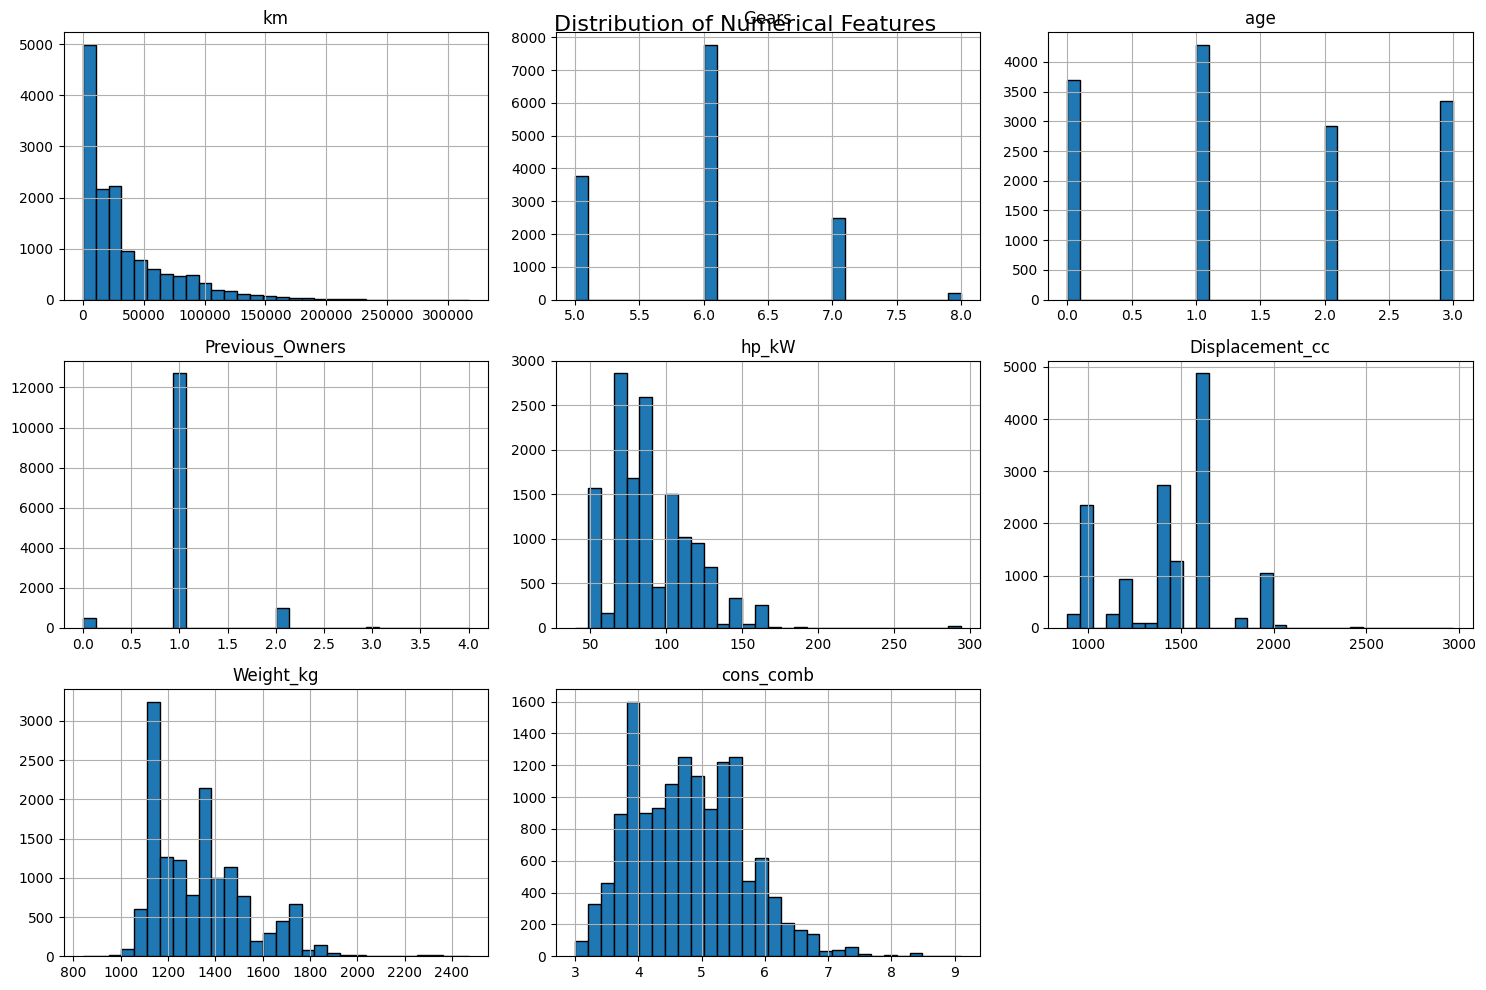

In [ ]:
from pandas.core.indexes import category


# Select numerical columns

numerical_features = car_df.select_dtypes(include=['int64', 'float64']).columns
#print(numerical_features)

numerical_features = numerical_features.drop('price')
print(numerical_features)


car_df[numerical_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.show()


#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

In [ ]:
# Identify categorical columns and check their frequency distributions


# Select categorical columns
categorical_cols = car_df.select_dtypes(include=['object', 'category']).columns
print(categorical_cols)

#Checking Frequency Distribution
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(car_df[col].value_counts(normalize=True) * 100)

Index(['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Comfort_Convenience',
       'Entertainment_Media', 'Extras', 'Safety_Security', 'Inspection_new',
       'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain'],
      dtype='object')

Column: make_model
make_model
Audi A3           19.365258
Opel Insignia     16.970931
Audi A1           16.690072
Opel Astra        16.184525
Opel Corsa        14.000843
Renault Clio      10.433928
Renault Espace     6.206993
Renault Duster     0.140430
Audi A2            0.007021
Name: proportion, dtype: float64

Column: body_type
body_type
Sedans           50.765342
Station wagon    23.908159
Compact          19.028226
Van               5.160792
Transporter       0.610869
Off-Road          0.294902
Coupe             0.175537
Convertible       0.056172
Name: proportion, dtype: float64

Column: vat
vat
VAT deductible      94.270468
Price negotiable     5.729532
Name: proportion, dtype: float64

Column: Type
Type
Used              71.42255

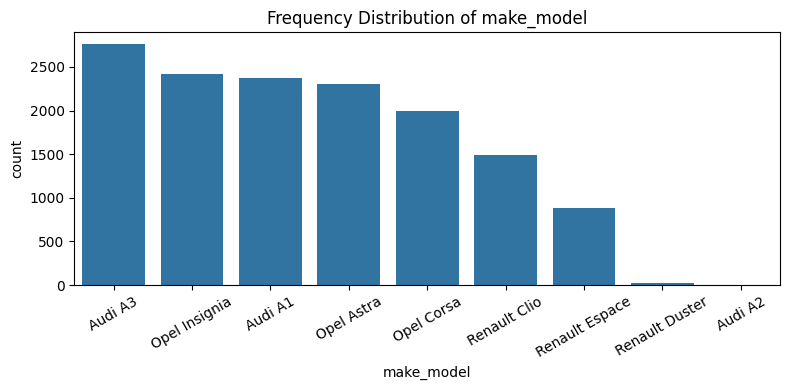

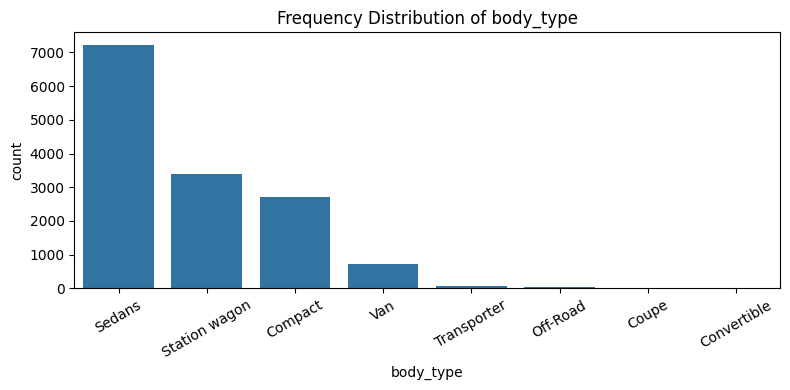

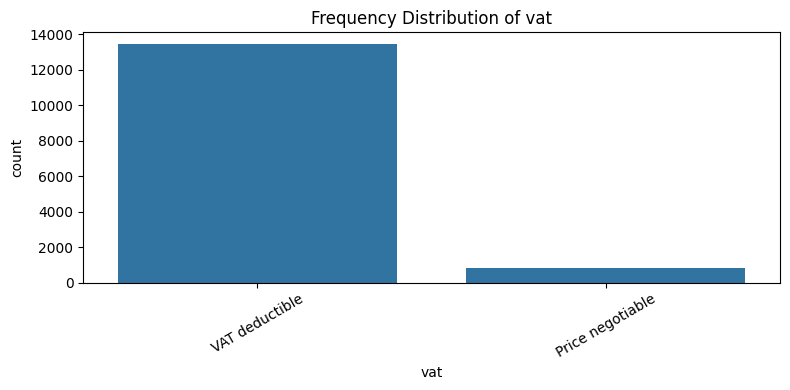

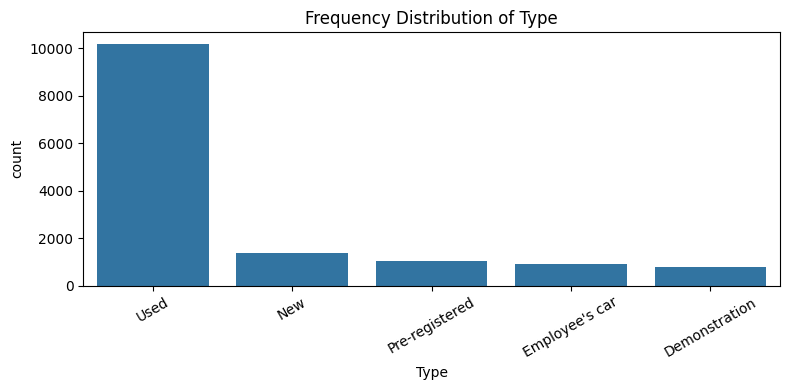

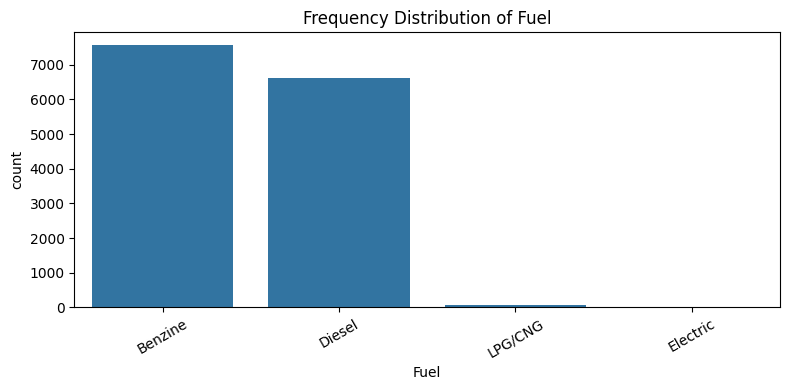

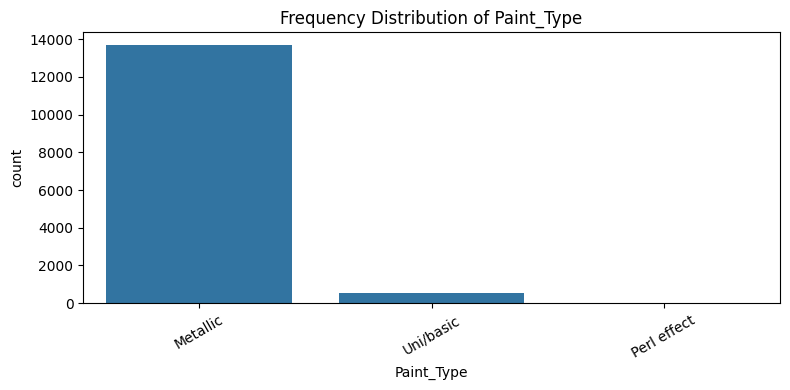

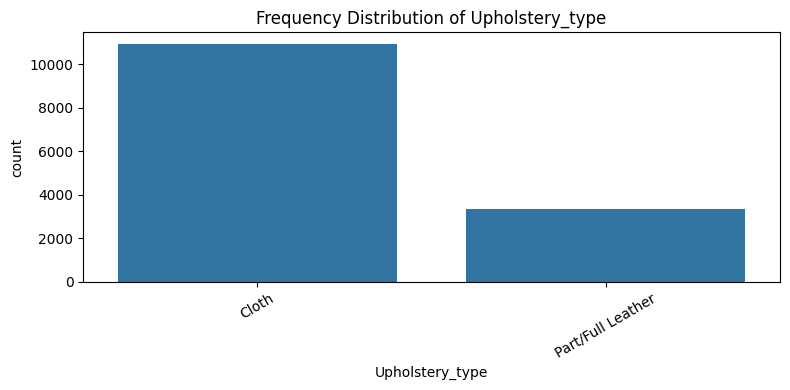

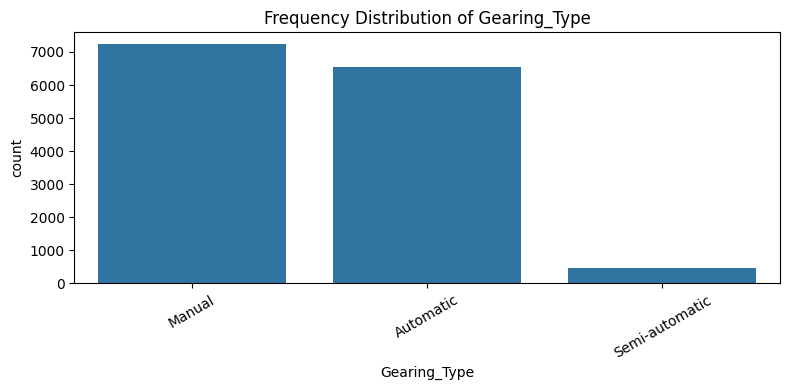

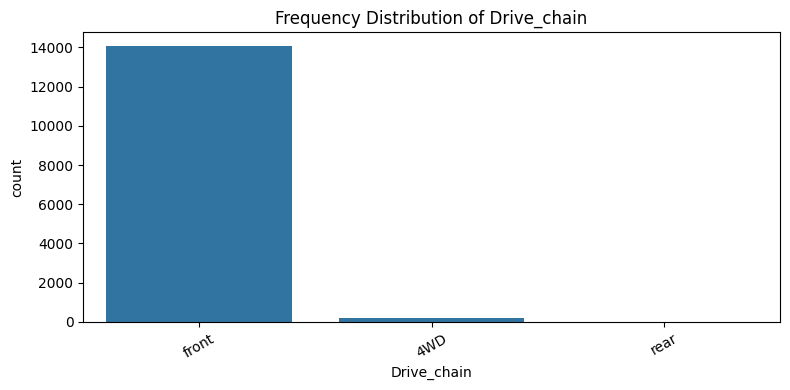

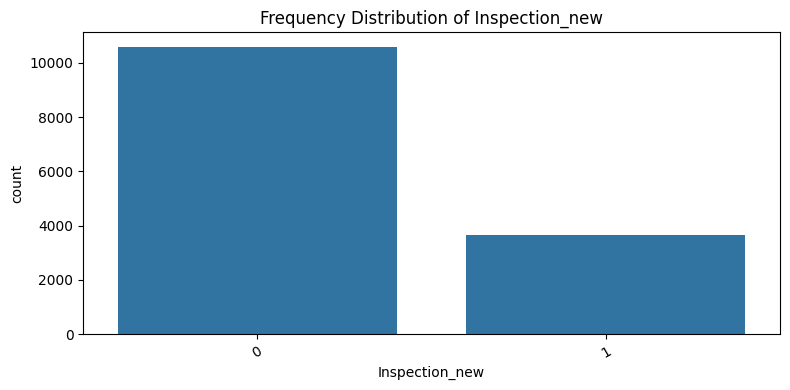

In [ ]:
#Visualise the distribution
cols = ['make_model', 'body_type', 'vat', 'Type', 'Fuel',
         'Paint_Type','Upholstery_type', 'Gearing_Type', 'Drive_chain', 'Inspection_new']


      # 'Safety_Security', 'Comfort_Convenience','Entertainment_Media', 'Extras',

for col in cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=car_df[col], order=car_df[col].value_counts().index)
    plt.title(f"Frequency Distribution of {col}")

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


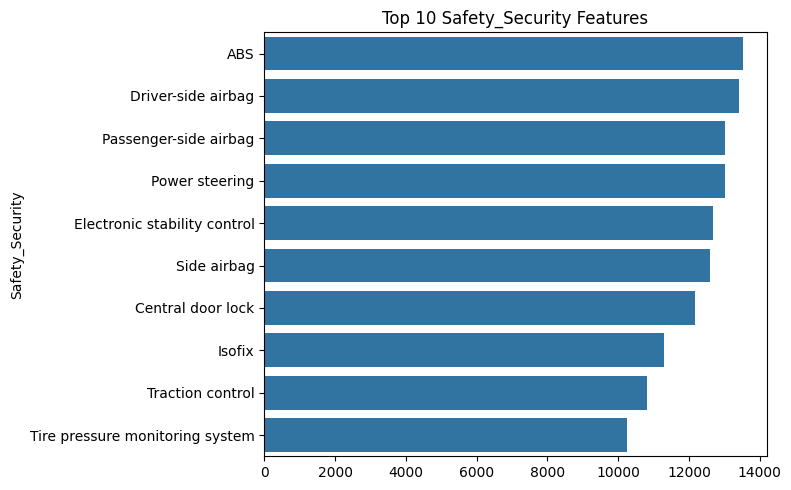

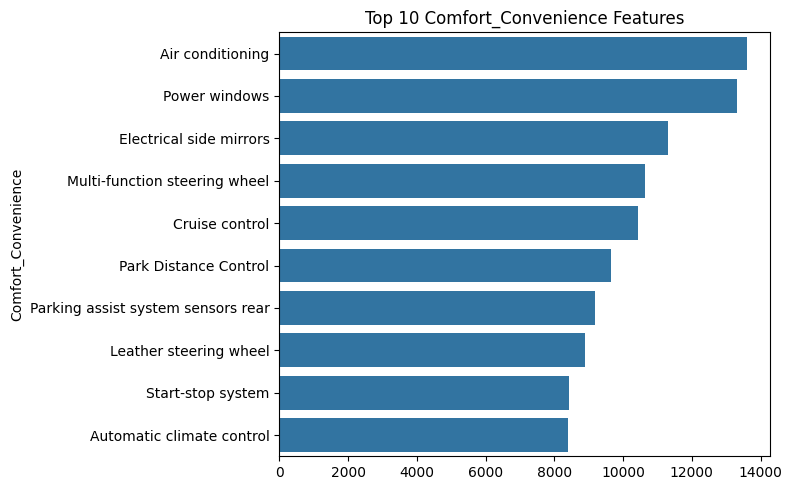

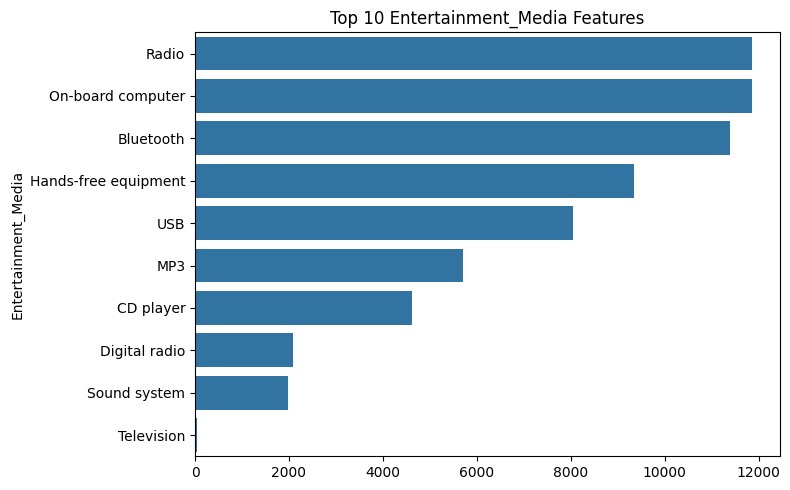

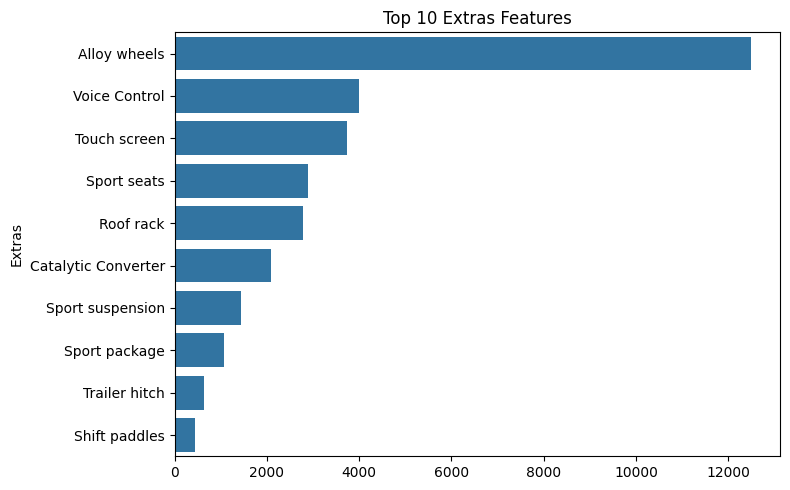

In [ ]:
multi_cols = ['Safety_Security', 'Comfort_Convenience',
              'Entertainment_Media', 'Extras']

for col in multi_cols:
    expanded = car_df[col].str.split(',').explode().str.strip()
    counts = expanded.value_counts().head(10)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=counts.values, y=counts.index)
    plt.title(f"Top 10 {col} Features")
    plt.tight_layout()
    plt.show()

**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

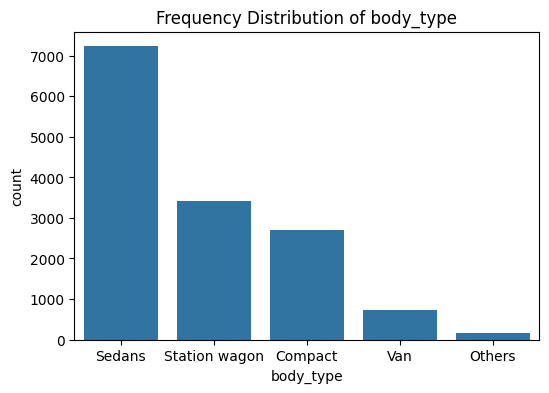

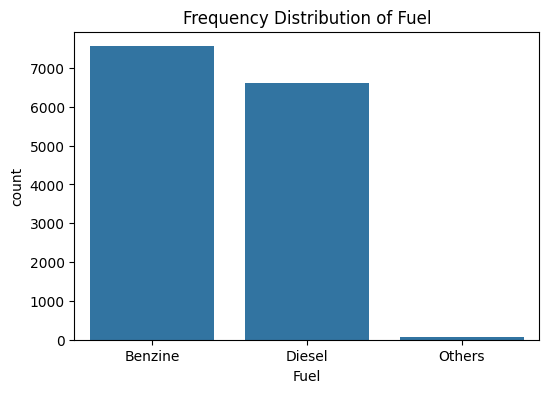

In [ ]:
# Fix columns as needed

#Body Type, Fuel and Paint type categorical variables have low frequency values.

#Body Type and Fuel - Rare values which is less than a threshold of 0.01 are combined as Others

def group_rare(series, threshold):
    freq = series.value_counts(normalize=True)
    rare_labels = freq[freq < threshold].index
    series.replace(rare_labels, 'Others', inplace=True)
    return series

group_rare(car_df['body_type'], 0.01)
group_rare(car_df['Fuel'], 0.01)\

cols = ['body_type', 'Fuel']
for col in cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=car_df[col], order=car_df[col].value_counts().index)
    plt.title(f"Frequency Distribution of {col}")
    plt.show()


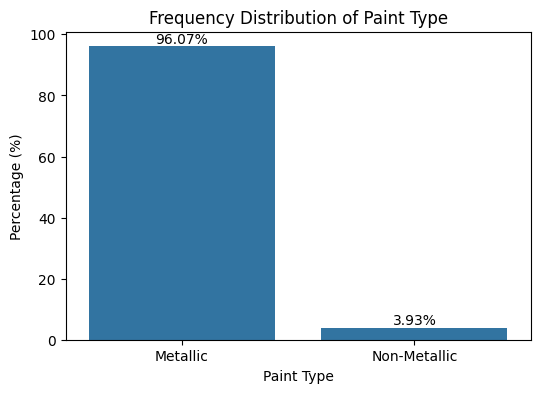

In [ ]:
#Perl Effect and uni/basic constitute very less percentage of values,
#hence they are combined and named as non- metallic

car_df['Paint_Type'] = car_df['Paint_Type'].replace({
    'Perl effect': 'Non-Metallic',
    'Uni/basic': 'Non-Metallic'
})


paint_dist = car_df['Paint_Type'].value_counts(normalize=True).reset_index()
paint_dist.columns = ['Paint_Type', 'Percentage']
paint_dist['Percentage'] = paint_dist['Percentage'] * 100

# Plot
plt.figure(figsize=(6,4))

sns.barplot(data=paint_dist, x='Paint_Type', y='Percentage')

plt.title("Frequency Distribution of Paint Type")
plt.xlabel("Paint Type")
plt.ylabel("Percentage (%)")

# Show values on bars
for i, val in enumerate(paint_dist['Percentage']):
    plt.text(i, val + 1, f"{val:.2f}%", ha='center')

plt.show()

#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

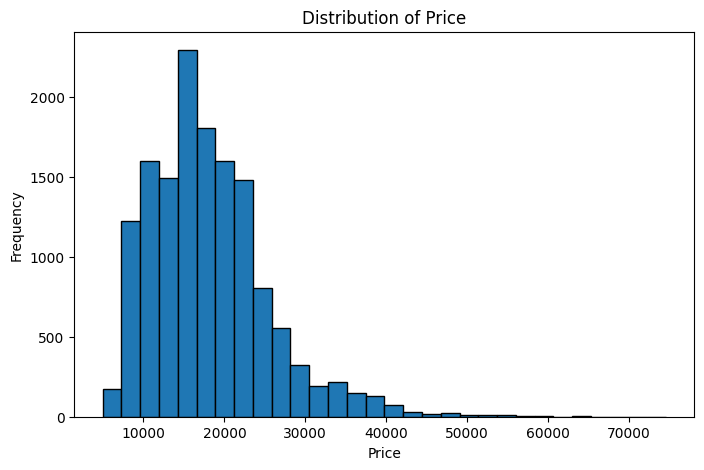

In [ ]:
# Plot histograms for target feature

plt.figure(figsize=(8, 5))
plt.hist(car_df['price'], bins=30, edgecolor='black')
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

 #Target feature is Right Skewed.
 #Majority of values are concentrated on the lower end, while a small number of high values extend the tail toward the right.

**The target variable seems to be skewed. Perform suitable transformation on the target.**

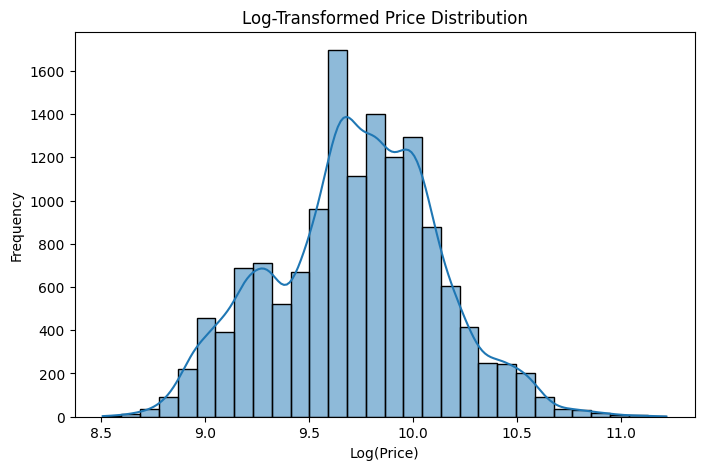

In [ ]:
# Transform the target feature

#Log transformation is applied on target feature as it is right skewed.
#It compresses larger values more than smaller ones.
#It reduces the impact of extreme values, shortens the right tail, and makes the distribution more symmetric and closer to normal.
#This improves the performance of regression models by stabilizing variance and reducing the influence of outliers.

car_df['price_log'] = np.log1p(car_df['price'])


plt.figure(figsize=(8, 5))
sns.histplot(car_df['price_log'], bins=30, kde=True)

plt.title("Log-Transformed Price Distribution")
plt.xlabel("Log(Price)")
plt.ylabel("Frequency")
plt.show()


In [ ]:
print("Skew Value before transformation:", car_df['price'].skew())
#Skew value is > 1 hence target feature is right skewed
print("Skew Values after transformation:", car_df['price_log'].skew())
#Skew value is 0, hence it is symmetric or normal distribution

Skew Value before transformation: 1.268475376698342
Skew Values after transformation: -0.03548951812903017


### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

price              0.961194
hp_kW              0.676764
Gears              0.585561
Weight_kg          0.456409
Displacement_cc    0.258258
cons_comb          0.209080
Previous_Owners   -0.156804
km                -0.422404
age               -0.483234
Name: price_log, dtype: float64


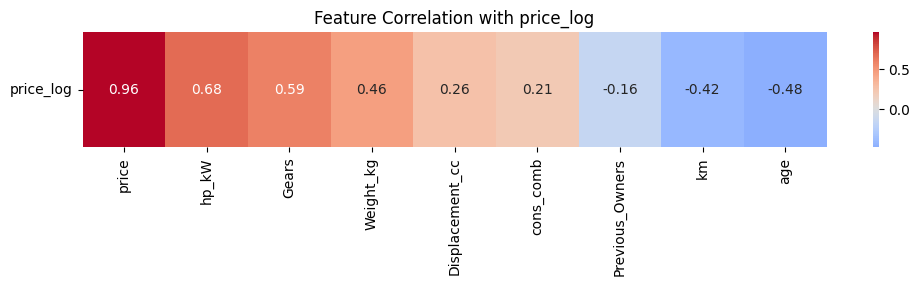

In [ ]:
# Visualise correlation

target = 'price_log'   # or 'price'
numeric_df = car_df.select_dtypes(include=['int64', 'float64'])

# Get correlation of all numeric features with target
corr_with_target = numeric_df.corr()[target].sort_values(ascending=False)

# Drop target itself from the list
corr_with_target = corr_with_target.drop(target)

print(corr_with_target)


#Correlation map showing Feature correlation with target variable price-log
plt.figure(figsize=(12, 1.5))
sns.heatmap(corr_with_target.to_frame().T, cmap='coolwarm', center=0, annot=True, fmt=".2f")
plt.title(f"Feature Correlation with {target}")
plt.yticks(rotation=0)
plt.show()


#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.


Average price by make_model:
       make_model         price
0  Renault Espace  30263.036199
1         Audi A2  28200.000000
2   Opel Insignia  21513.868846
3         Audi A3  20945.149021
4         Audi A1  18726.660496
5      Opel Astra  15905.897180
6  Renault Duster  13006.900000
7    Renault Clio  11988.452221
8      Opel Corsa  11031.192578


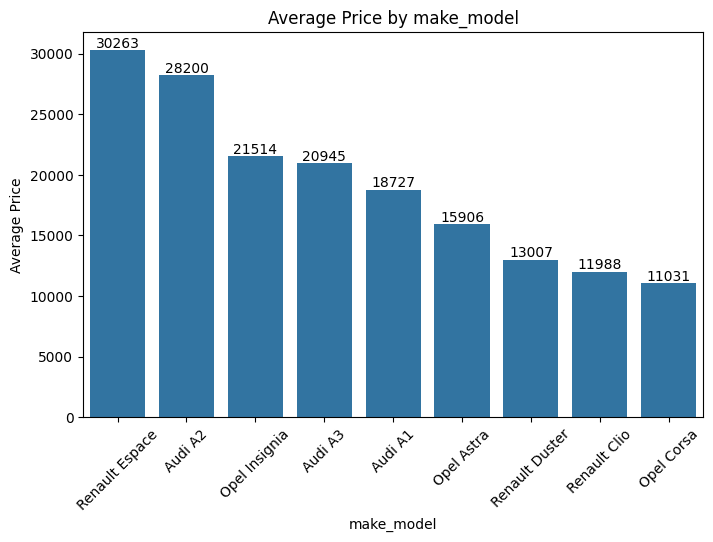


Average price by body_type:
       body_type         price
0            Van  30790.629932
1  Station wagon  18646.015272
2         Sedans  17675.357676
3         Others  17371.777778
4        Compact  15153.560148


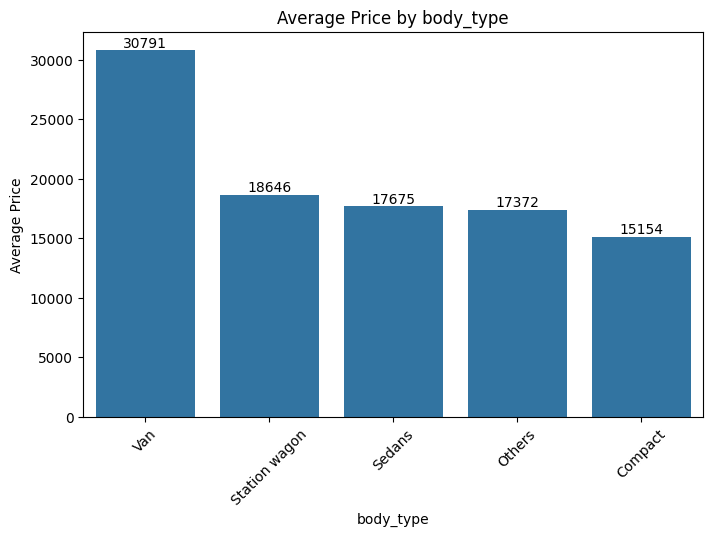


Average price by vat:
                vat         price
0    VAT deductible  18260.229704
1  Price negotiable  15480.591912


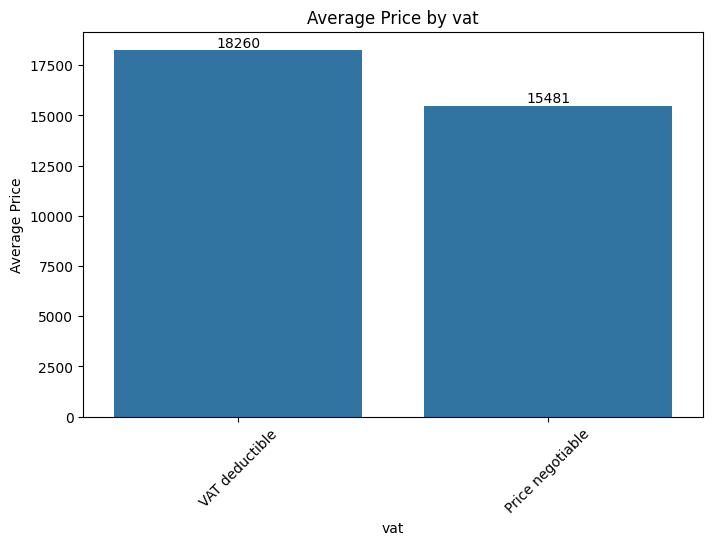


Average price by Type:
             Type         price
0   Demonstration  26021.249022
1             New  24062.222790
2  Pre-registered  21077.724976
3  Employee's car  18382.721547
4            Used  16375.263862


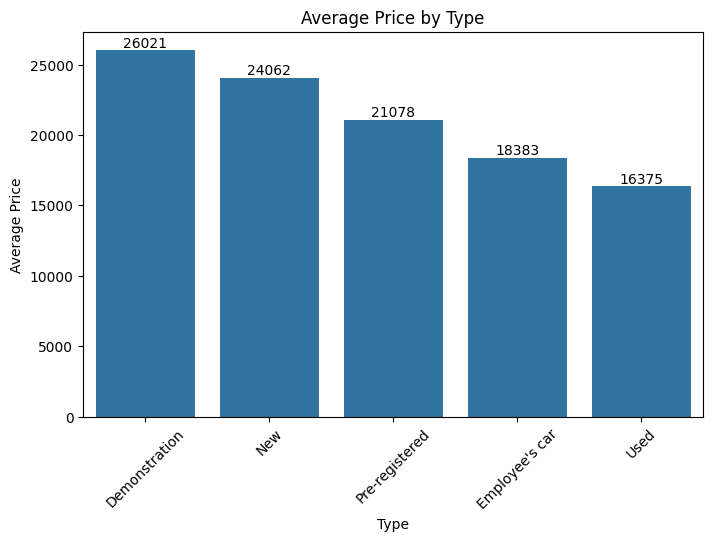


Average price by Fuel:
      Fuel         price
0   Diesel  18344.191419
1  Benzine  17893.938211
2   Others  17406.446154


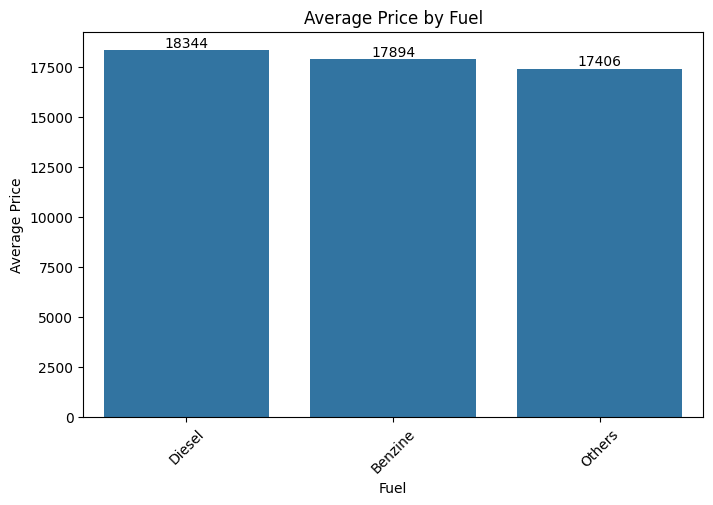


Average price by Paint_Type:
     Paint_Type         price
0      Metallic  18150.512498
1  Non-Metallic  16890.526786


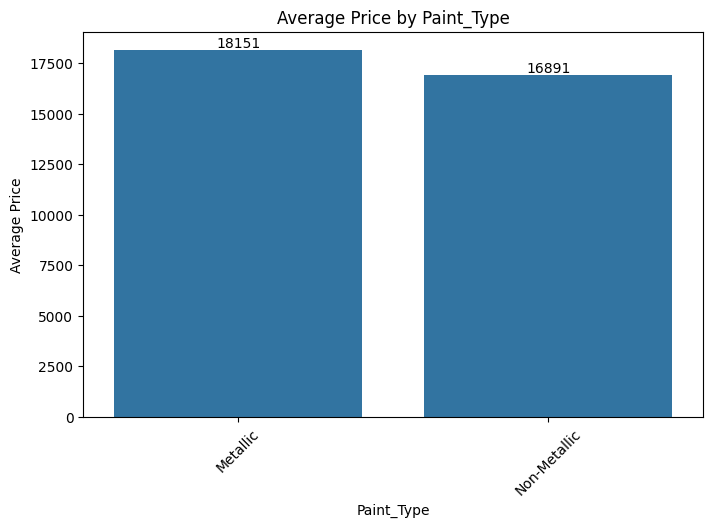


Average price by Upholstery_type:
     Upholstery_type         price
0  Part/Full Leather  23411.920878
1              Cloth  16484.043048


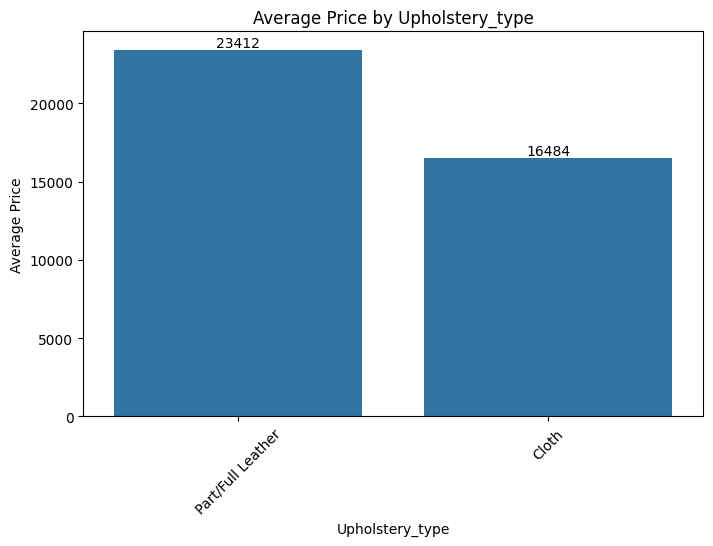


Average price by Gearing_Type:
     Gearing_Type         price
0  Semi-automatic  23281.364224
1       Automatic  21156.677819
2          Manual  15002.743501


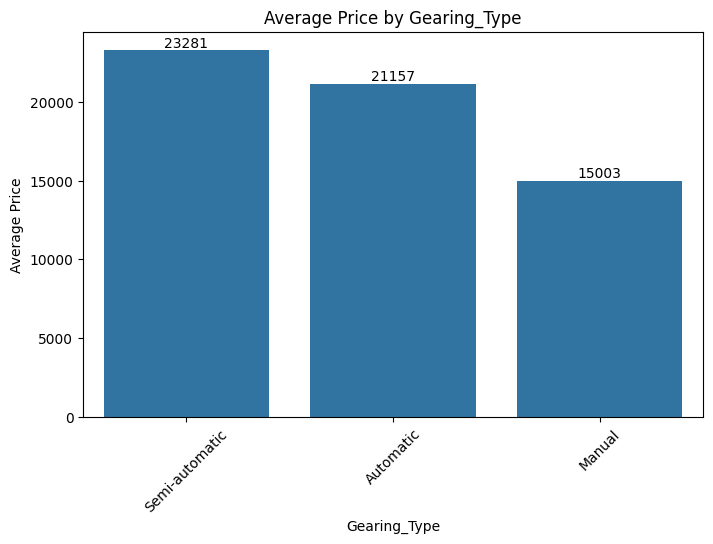


Average price by Drive_chain:
  Drive_chain        price
0         4WD  28983.80117
1       front  17969.46378
2        rear  15332.50000


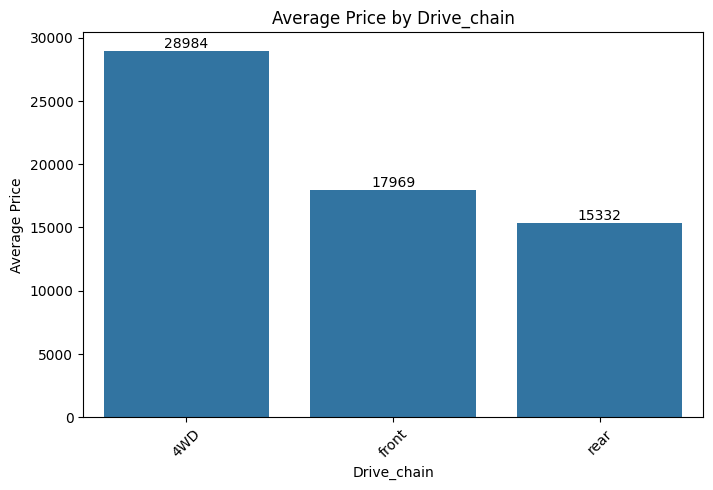


Average price by Inspection_new:
  Inspection_new         price
0              1  18135.282466
1              0  18089.145204


/tmp/ipykernel_3208/97349035.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  car_df.groupby(col)['price']


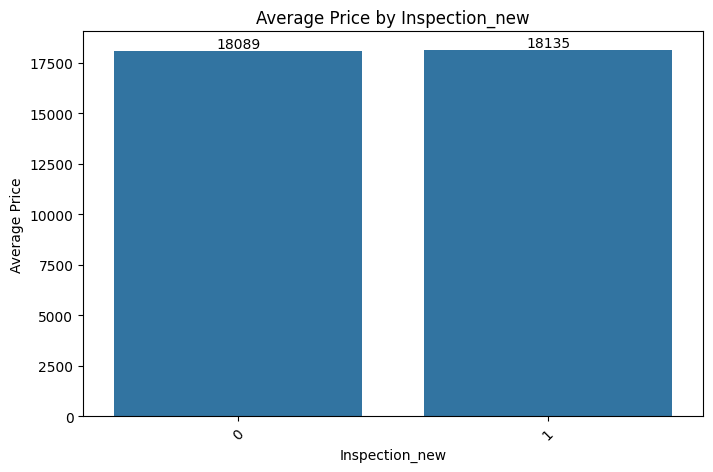

In [ ]:
# Comparing average values of target for different categories

categorical_cols = [
    'make_model',
    'body_type',
    'vat',
    'Type',
    'Fuel',
    'Paint_Type',
    'Upholstery_type',
    'Gearing_Type',
    'Drive_chain',
    'Inspection_new'
]

for col in categorical_cols:
    avg_price_df = (
        car_df.groupby(col)['price']
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    print(f"\nAverage price by {col}:")
    print(avg_price_df)

    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=avg_price_df, x=col, y='price')

    plt.title(f'Average Price by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Price')
    plt.xticks(rotation=45)

    for p in ax.patches:
        ax.annotate(f'{p.get_height():.0f}',
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom')

    plt.show()


### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

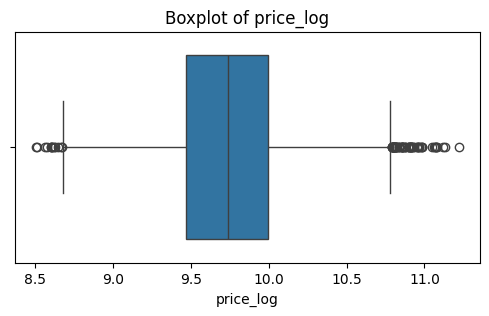

In [ ]:
# Outliers present in each column

#Plot box plot to see the outliers of the target variable price_log
plt.figure(figsize=(6, 3))
sns.boxplot(x=car_df['price_log'])

plt.title("Boxplot of price_log")
plt.show()

In [ ]:
# Outliers in the numerical predictors

In [ ]:
num_cols = car_df.select_dtypes(include=['int64', 'float64']).columns

# Remove target variable
num_cols = num_cols.drop(['price', 'price_log'], errors='ignore')
print(num_cols)

Index(['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Displacement_cc',
       'Weight_kg', 'cons_comb'],
      dtype='object')


In [ ]:
outlier_summary = {}

for col in num_cols:
    Q1 = car_df[col].quantile(0.25)
    Q3 = car_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = car_df[(car_df[col] < lower) | (car_df[col] > upper)]

    outlier_summary[col] = len(outliers)

# Convert to dataframe
outlier_df = pd.DataFrame.from_dict(outlier_summary, orient='index', columns=['outlier_count'])

print(outlier_df.sort_values(by='outlier_count', ascending=False))

                 outlier_count
Previous_Owners           1542
km                         657
hp_kW                      298
Gears                      203
cons_comb                  111
Weight_kg                   73
Displacement_cc             21
age                          0


#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

In [ ]:
# Handle outliers

#Retain all the outliers in the target variable as they are only few and
#Cap the outliers in numerical predictors

print('Before Outlier Analysis', car_df.shape)

for col in num_cols:
    Q1 = car_df[col].quantile(0.25)
    Q3 = car_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    car_df[col] = car_df[col].clip(lower, upper)

print('After Outlier Analysis', car_df.shape)

Before Outlier Analysis (14242, 24)
After Outlier Analysis (14242, 24)


### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [ ]:
# Fix/create columns as needed

#Print the columns count before fixing or creating new columns
print(car_df.columns)
print('\n\nNumber of Columns : ',car_df.shape[1])

Index(['make_model', 'body_type', 'price', 'vat', 'km', 'Type', 'Fuel',
       'Gears', 'Comfort_Convenience', 'Entertainment_Media', 'Extras',
       'Safety_Security', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new',
       'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Displacement_cc',
       'Weight_kg', 'Drive_chain', 'cons_comb', 'price_log'],
      dtype='object')


Number of Columns :  24


In [ ]:
#Drop columns with only one value

low_variance_cols = [col for col in car_df.columns if car_df[col].nunique() <= 1]
print(low_variance_cols)


#Though we get previous owners as redundant column from the above code, has only 1 has values for all the rows
#I would like to retain this predictor as it is unique information and is not duplicating any other columns
#gives valuable information about determining car price

['Previous_Owners']


#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [ ]:
# Check unique values in each feature spec column

#Validate the count of values in percentage for each value in the multivariate Categorical Columns
multi_cols = ['Safety_Security', 'Comfort_Convenience',
              'Entertainment_Media', 'Extras']

#Find the counts for all the values in multivariate categorical Columns
for col in multi_cols:
    expanded = car_df[col].str.split(',').explode().str.strip()
    counts = expanded.value_counts(normalize=True)*100
    print(f'{col} : {counts}')

#Handling multivariate Categorical Columns and adding the values to
#original car_df dataset for price prediction

from sklearn.preprocessing import MultiLabelBinarizer

def process_multilabel_column(df, column_name, threshold=0.01):
    """
    df: original dataframe
    column_name: multi-label column (string with comma-separated values)
    threshold: minimum frequency to keep feature (default = 1%)
    """

    # Step 1: Convert string to list
    split_series = df[column_name].fillna('').apply(
        lambda x: [item.strip() for item in x.split(',') if item.strip() != '']
    )

    # Step 2: Apply MultiLabelBinarizer
    mlb = MultiLabelBinarizer()
    encoded_df = pd.DataFrame(
        mlb.fit_transform(split_series),
        columns=mlb.classes_,
        index=df.index
    )

    # Step 3: Calculate frequency (proportion)
    freq = encoded_df.mean()

    # Step 4: Remove features < threshold
    cols_to_keep = freq[freq >= threshold].index
    filtered_df = encoded_df[cols_to_keep]

    print(f"\n{column_name}")
    print(f"Original features: {encoded_df.shape[1]}")
    print(f"Remaining features after filtering: {filtered_df.shape[1]}")

    # Step 5: Add back to original dataframe
    df = pd.concat([df, filtered_df], axis=1)

    return df, filtered_df


multilabel_cols = [
    'Safety_Security',
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras'
]

for col in multilabel_cols:
    car_df, _ = process_multilabel_column(car_df, col, threshold=0.01)


Safety_Security : Safety_Security
ABS                                      7.335583
Driver-side airbag                       7.279710
Passenger-side airbag                    7.063272
Power steering                           7.055135
Electronic stability control             6.883720
Side airbag                              6.838154
Central door lock                        6.597848
Isofix                                   6.125914
Traction control                         5.862282
Tire pressure monitoring system          5.565018
Immobilizer                              5.537353
Daytime running lights                   5.464122
Fog lights                               4.334736
LED Daytime Running Lights               2.895068
Xenon headlights                         1.856814
Emergency brake assistant                1.650682
LED Headlights                           1.601319
Lane departure warning system            1.600777
Central door lock with remote control    1.276390
Head airbag     

Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [ ]:
# Drop features from df

#Count the multi label features
def count_features(col):
    return car_df[col].fillna('').apply(
        lambda x: len([item for item in x.split(',') if item.strip()])
    )

car_df['num_safety_features'] = count_features('Safety_Security')
car_df['num_comfort_features'] = count_features('Comfort_Convenience')
car_df['num_entertainment_features'] = count_features('Entertainment_Media')
car_df['num_extra_features'] = count_features('Extras')


In [ ]:
#Drop multilabel features

multilabel_cols = [
    'Safety_Security',
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras'
]

car_df.drop(columns=multilabel_cols, inplace=True)

car_df.shape

(14242, 107)

In [ ]:
#Drop highly sparse columns

zero_percent = (car_df == 0).sum() / len(car_df) * 100
sparse_cols = zero_percent[zero_percent > 95].index
print(sparse_cols)
car_df.drop(columns=sparse_cols, inplace=True)

car_df.shape

Index(['Driver drowsiness detection', 'Auxiliary heating', 'Heads-up display',
       'Massage seats', 'Panorama roof', 'Sunroof', 'Cab or rented Car',
       'Shift paddles', 'Ski bag', 'Trailer hitch', 'Winter tyres'],
      dtype='object')


(14242, 96)

#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [ ]:
# Encode features


categorical_cols = [
    'make_model',
    'body_type',
    'vat',
    'Type',
    'Fuel',
    'Paint_Type',
    'Upholstery_type',
    'Gearing_Type',
    'Drive_chain'
  ]

car_df = pd.get_dummies(car_df, columns=categorical_cols, drop_first=True)


In [ ]:
#car_df.head(5)

#car_df.select_dtypes(include=['object']).columns
#car_df.drop(columns=['Type'], inplace=True)

car_df.columns

Index(['price', 'km', 'Gears', 'age', 'Previous_Owners', 'hp_kW',
       'Inspection_new', 'Displacement_cc', 'Weight_kg', 'cons_comb',
       ...
       'Type_Pre-registered', 'Type_Used', 'Fuel_Diesel', 'Fuel_Others',
       'Paint_Type_Non-Metallic', 'Upholstery_type_Part/Full Leather',
       'Gearing_Type_Manual', 'Gearing_Type_Semi-automatic',
       'Drive_chain_front', 'Drive_chain_rear'],
      dtype='object', length=112)

#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [ ]:
# Split data

#Define X and y

X = car_df.drop(columns=['price', 'price_log'], errors='ignore')
y = car_df['price_log']

#Perform Train-TestSplit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#Print the shape of trainand test Dataset

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (9969, 110)
X_test shape: (4273, 110)
y_train shape: (9969,)
y_test shape: (4273,)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [ ]:
# Scale features
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to DataFrame
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)


## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [ ]:
# Initialise and train model

# Initialize model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train_scaled, y_train)


# Predict on test data
y_pred_log_train = lr_model.predict(X_train_scaled)
y_pred_log_test = lr_model.predict(X_test_scaled)

#Convert predictions back to Original Scale
y_pred_train = np.expm1(y_pred_log_train)
y_pred_test = np.expm1(y_pred_log_test)
y_actual = np.expm1(y_test)


In [ ]:
# Evaluate the model's performance

rmse = np.sqrt(mean_squared_error(y_actual, y_pred_test))
r2 = r2_score(y_actual, y_pred_test)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 2329.269832942906
R2 Score: 0.9025734828869397


#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

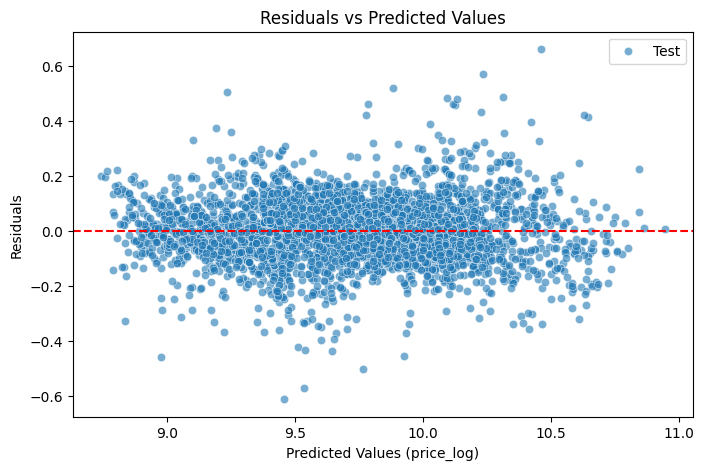

In [ ]:
# Linearity check: Plot residuals vs fitted values

residuals_train = y_train - y_pred_log_train
residuals_test = y_test - y_pred_log_test


plt.figure(figsize=(8, 5))


#sns.scatterplot(x=y_pred_log_train, y=residuals_train, label = 'Train', alpha = 0.6)
sns.scatterplot(x=y_pred_log_test, y=residuals_test, label = 'Test', alpha = 0.6)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Values (price_log)")
plt.ylabel("Residuals")

plt.show()


#Residuals were plotted against predicted values to assess the linearity assumption of the regression model.
#The residuals were randomly distributed around zero with no clear pattern,
#indicating that the linearity assumption holds.
#This suggests that the model captures the relationship between predictors and the target variable effectively.

Check normality in residual distribution

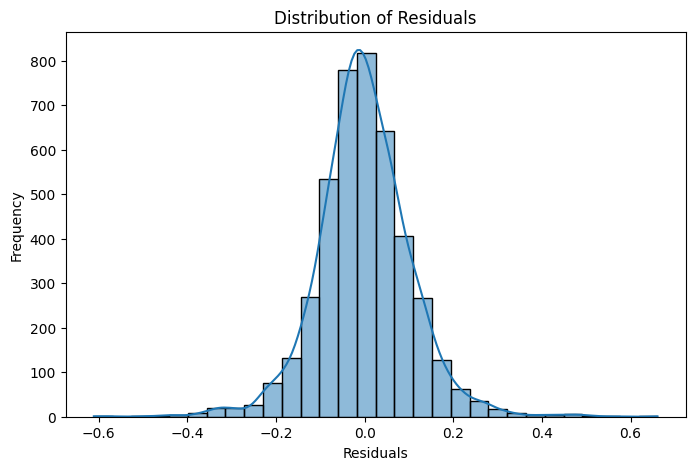

In [ ]:
# Check the normality of residuals by plotting their distribution


plt.figure(figsize=(8, 5))

sns.histplot(residuals_test, kde=True, bins=30)

plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.show()


Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [ ]:
# Check for multicollinearity and handle


from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use scaled data for VIF (recommended)
X = X_train_scaled.copy()

# Add constant (required for VIF)
X['constant'] = 1

# Compute VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# Remove constant
vif_data = vif_data[vif_data['Feature'] != 'constant']

# Sort VIF
vif_data = vif_data.sort_values(by='VIF', ascending=False)

print(vif_data)

/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


                        Feature          VIF
83   num_entertainment_features  1306.585640
81          num_safety_features   515.434730
82         num_comfort_features   235.044543
72                          USB    82.091829
68                          MP3    79.637243
..                          ...          ...
104     Paint_Type_Non-Metallic     1.126444
103                 Fuel_Others     1.086096
109            Drive_chain_rear     1.039379
3               Previous_Owners          NaN
85           make_model_Audi A2          NaN

[110 rows x 2 columns]


In [ ]:
high_vif_features = vif_data[vif_data['VIF'] > 5]['Feature']
print(high_vif_features)

83                num_entertainment_features
81                       num_safety_features
82                      num_comfort_features
72                                       USB
68                                       MP3
67                      Hands-free equipment
65                                 CD player
64                                 Bluetooth
70                                     Radio
69                         On-board computer
66                             Digital radio
71                              Sound system
84                        num_extra_features
92                 make_model_Renault Espace
21                                Fog lights
25                LED Daytime Running Lights
4                                      hp_kW
16                    Daytime running lights
32           Tire pressure monitoring system
23                               Immobilizer
27             Lane departure warning system
35                          Xenon headlights
19        

### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [ ]:
# List of alphas to tune for Ridge regularisation
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alpha_list = np.logspace(-4, 3, 30)   # from 0.0001 to 1000
print(alpha_list)

[1.00000000e-04 1.74332882e-04 3.03919538e-04 5.29831691e-04
 9.23670857e-04 1.61026203e-03 2.80721620e-03 4.89390092e-03
 8.53167852e-03 1.48735211e-02 2.59294380e-02 4.52035366e-02
 7.88046282e-02 1.37382380e-01 2.39502662e-01 4.17531894e-01
 7.27895384e-01 1.26896100e+00 2.21221629e+00 3.85662042e+00
 6.72335754e+00 1.17210230e+01 2.04335972e+01 3.56224789e+01
 6.21016942e+01 1.08263673e+02 1.88739182e+02 3.29034456e+02
 5.73615251e+02 1.00000000e+03]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [ ]:
# Applying Ridge regression

ridge = Ridge()

param_grid = {'alpha': alpha_list}

model_cv = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True,
    verbose=5
)

model_cv.fit(X_train_scaled, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV 1/5] END alpha=0.0001;, score=(train=-0.078, test=-0.080) total time=   0.1s
[CV 2/5] END alpha=0.0001;, score=(train=-0.079, test=-0.080) total time=   0.1s
[CV 3/5] END alpha=0.0001;, score=(train=-0.078, test=-0.081) total time=   0.1s
[CV 4/5] END alpha=0.0001;, score=(train=-0.079, test=-0.080) total time=   0.2s
[CV 5/5] END alpha=0.0001;, score=(train=-0.079, test=-0.079) total time=   0.2s
[CV 1/5] END alpha=0.00017433288221999874;, score=(train=-0.078, test=-0.080) total time=   0.1s
[CV 2/5] END alpha=0.00017433288221999874;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 3/5] END alpha=0.00017433288221999874;, score=(train=-0.078, test=-0.081) total time=   0.0s
[CV 4/5] END alpha=0.00017433288221999874;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 5/5] END alpha=0.00017433288221999874;, score=(train=-0.079, test=-0.079) total time=   0.0s
[CV 1/5] END alpha=0.0003039195382313198;, score

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': array([1.00000000e-04, 1.74332882e-04, 3.03919538e-04, 5.29831691e-04,
       9.23670857e-04, 1.61026203e-03, 2.80721620e-03, 4.89390092e-03,
       8.53167852e-03, 1.48735211e-02, 2.59294380e-02, 4.52035366e-02,
       7.88046282e-02, 1.37382380e-01, 2.39502662e-01, 4.17531894e-01,
       7.27895384e-01, 1.26896100e+00, 2.21221629e+00, 3.85662042e+00,
       6.72335754e+00, 1.17210230e+01, 2.04335972e+01, 3.56224789e+01,
       6.21016942e+01, 1.08263673e+02, 1.88739182e+02, 3.29034456e+02,
       5.73615251e+02, 1.00000000e+03])},
             return_train_score=True, scoring='neg_mean_absolute_error',
             verbose=5)

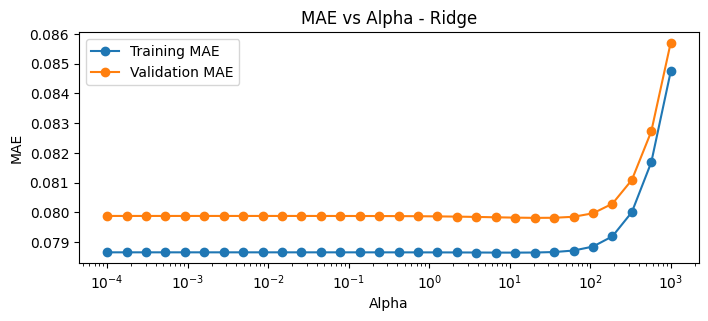

In [ ]:
# Plot train and test scores against alpha

cv_results = pd.DataFrame(model_cv.cv_results_)
#cv_results.columns


cv_results['param_alpha'] = cv_results['param_alpha'].astype(float)

plt.figure(figsize= (8,3))
plt.plot(cv_results['param_alpha'], np.abs(cv_results['mean_train_score']), marker='o', label='Training MAE')
plt.plot(cv_results['param_alpha'], np.abs(cv_results['mean_test_score']), marker='o', label='Validation MAE')

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('MAE vs Alpha - Ridge')
plt.legend()
plt.show()


#Both training and validation errors remain relatively constant across a wide range of alpha values,
#Model is stable and not highly sensitive to regularization.
# The best alpha value corresponds to the region where validation MAE is minimum, which lies in the lower alpha range.
# A sharp increase in error at higher alpha values indicates underfitting due to excessive regularization.



# the optimal alpha is selected from the region where validation MAE is minimized
# Avoiding extremely small values that provide little regularization and
# very large values that lead to underfitting.
# values between 0.01 and 10 are preferred, as they offer a balance between model simplicity and performance




Find the best alpha value.

In [ ]:
# Best alpha value

best_ridge_alpha = np.round(model_cv.best_params_['alpha'],4)
best_score = abs(np.round(model_cv.best_score_,4))
print('Best ridge alpha value: ', best_ridge_alpha)
print('Best MAE: ', best_score)

Best ridge alpha value:  20.4336
Best MAE:  0.0798


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [ ]:
# Take a smaller range of alpha to test

best_alpha = 20.4336

lower = best_alpha / 2
upper = best_alpha * 2

refined_alpha_list = np.logspace(np.log10(lower), np.log10(upper), 30)

print(refined_alpha_list)

#After obtaining the initial best alpha value of 20.4366,
#a smaller range was defined around this value to refine the tuning.
#A range of 5 to 25 was selected to explore values close to the optimal region.
#This allows a more precise selection of the regularization parameter by focusing on a
#narrower interval around the previously identified best alpha.

[10.2168     10.717058   11.24181077 11.79225766 12.36965678 12.97532781
 13.61065507 14.27709066 14.97615777 15.70945419 16.47865591 17.28552103
 18.13189369 19.01970837 19.95099422 20.9278798  21.95259785 23.02749045
 24.15501438 25.33774667 26.57839056 27.87978167 29.24489441 30.67684889
 32.17891795 33.75453471 35.40730036 37.14099246 38.9595735  40.8672    ]


In [ ]:
# Applying Ridge regression

ridge_refined = Ridge()

refined_param_grid = {'alpha': refined_alpha_list}

ridge_refined_cv = GridSearchCV(
    estimator=ridge_refined,
    param_grid=refined_param_grid,
    scoring='neg_mean_absolute_error',   # as requested
    cv=5,
    return_train_score=True,
    verbose=5
)

ridge_refined_cv.fit(X_train_scaled, y_train)


cv_results_refined = pd.DataFrame(ridge_refined_cv.cv_results_)
cv_results_refined['param_alpha'] = cv_results_refined['param_alpha'].astype(float)

cv_results_refined.head()

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV 1/5] END alpha=10.2168;, score=(train=-0.078, test=-0.080) total time=   0.2s
[CV 2/5] END alpha=10.2168;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 3/5] END alpha=10.2168;, score=(train=-0.078, test=-0.081) total time=   0.0s
[CV 4/5] END alpha=10.2168;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 5/5] END alpha=10.2168;, score=(train=-0.079, test=-0.079) total time=   0.0s
[CV 1/5] END alpha=10.71705800378438;, score=(train=-0.078, test=-0.080) total time=   0.0s
[CV 2/5] END alpha=10.71705800378438;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 3/5] END alpha=10.71705800378438;, score=(train=-0.078, test=-0.081) total time=   0.0s
[CV 4/5] END alpha=10.71705800378438;, score=(train=-0.079, test=-0.080) total time=   0.0s
[CV 5/5] END alpha=10.71705800378438;, score=(train=-0.079, test=-0.079) total time=   0.0s
[CV 1/5] END alpha=11.241810768193446;, score=(train=-0.078, test=-0

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.060214,0.072217,0.005711,0.003225,10.216800,{'alpha': 10.2168},-0.079872,-0.080124,-0.080622,-0.079810,-0.078679,-0.079822,0.000639,30,-0.078478,-0.078843,-0.078481,-0.078581,-0.078820,-0.078641,0.00016
1,0.023999,0.001324,0.003962,0.000086,10.717058,{'alpha': 10.71705800378438},-0.079874,-0.080120,-0.080621,-0.079811,-0.078677,-0.079821,0.000639,29,-0.078478,-0.078843,-0.078481,-0.078581,-0.078820,-0.078641,0.00016
2,0.038414,0.023244,0.004779,0.001574,11.241811,{'alpha': 11.241810768193446},-0.079877,-0.080116,-0.080620,-0.079813,-0.078674,-0.079820,0.000639,28,-0.078478,-0.078843,-0.078482,-0.078581,-0.078820,-0.078641,0.00016
3,0.035683,0.018876,0.008529,0.005614,11.792258,{'alpha': 11.792257660940512},-0.079879,-0.080111,-0.080619,-0.079814,-0.078671,-0.079819,0.000640,27,-0.078478,-0.078843,-0.078482,-0.078582,-0.078820,-0.078641,0.00016
4,0.040274,0.027866,0.005235,0.001598,12.369657,{'alpha': 12.36965677588581},-0.079882,-0.080107,-0.080618,-0.079815,-0.078668,-0.079818,0.000640,25,-0.078478,-0.078842,-0.078482,-0.078582,-0.078819,-0.078641,0.00016


Plot the error-alpha graph again and find the actual optimal value for alpha.

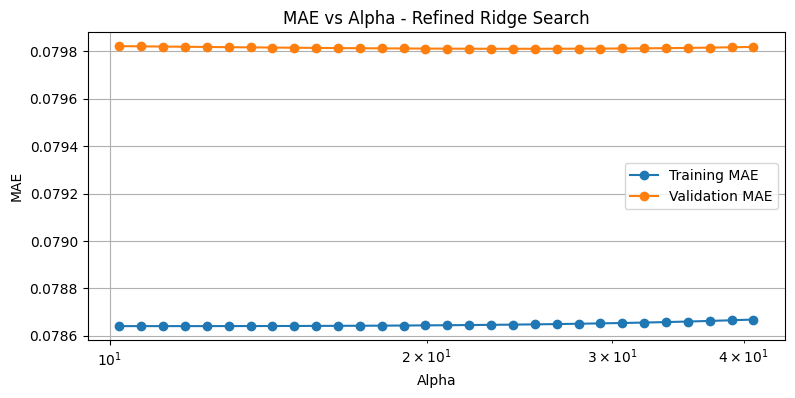

Best refined alpha value: 24.15501437620306
Best score (negative MAE): -0.07981042016857383
Best MAE: 0.07981042016857383


In [ ]:
# Plot train and test scores against alpha

plt.figure(figsize=(9, 4))

plt.plot(
    cv_results_refined['param_alpha'],
    np.abs(cv_results_refined['mean_train_score']),
    marker='o',
    label='Training MAE'
)

plt.plot(
    cv_results_refined['param_alpha'],
    np.abs(cv_results_refined['mean_test_score']),
    marker='o',
    label='Validation MAE'
)

plt.xscale('log')   # very important because alpha is on log scale
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('MAE vs Alpha - Refined Ridge Search')
plt.legend()
plt.grid(True)
plt.show()


# Best alpha value

best_refined_alpha = ridge_refined_cv.best_params_['alpha']
print("Best refined alpha value:", best_refined_alpha)


# Best score (negative MAE)
best_refined_score = ridge_refined_cv.best_score_
print("Best score (negative MAE):", best_refined_score)
print("Best MAE:", abs(best_refined_score))

In [ ]:
# Set best alpha for Ridge regression
best_ridge_model = Ridge(alpha=best_refined_alpha)

# Fit the Ridge model to get the coefficients of the fitted model
best_ridge_model.fit(X_train_scaled, y_train)




Ridge(alpha=np.float64(24.15501437620306))

In [ ]:
# Show the coefficients for each feature

ridge_coefficients = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': best_ridge_model.coef_
}).sort_values(by='Coefficient', ascending=False)

print(ridge_coefficients)

                         Feature  Coefficient
4                          hp_kW     0.101665
82          num_comfort_features     0.051707
86            make_model_Audi A3     0.037995
92     make_model_Renault Espace     0.036167
107  Gearing_Type_Semi-automatic     0.018418
..                           ...          ...
87         make_model_Opel Astra    -0.079072
2                            age    -0.090346
0                             km    -0.092579
90       make_model_Renault Clio    -0.120086
88         make_model_Opel Corsa    -0.149719

[110 rows x 2 columns]


In [ ]:
# Evaluate the Ridge model on the test data

y_pred_log_ridge = best_ridge_model.predict(X_test_scaled)



mae_log = mean_absolute_error(y_test, y_pred_log_ridge)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log_ridge))
r2_log = r2_score(y_test, y_pred_log_ridge)

print("Evaluation on log scale:")
print("MAE (log):", mae_log)
print("RMSE (log):", rmse_log)
print("R2 (log):", r2_log)



y_pred_ridge = np.expm1(y_pred_log_ridge)
y_actual = np.expm1(y_test)

mae_original = mean_absolute_error(y_actual, y_pred_ridge)
rmse_original = np.sqrt(mean_squared_error(y_actual, y_pred_ridge))
r2_original = r2_score(y_actual, y_pred_ridge)

print("\nEvaluation on original price scale:")
print("MAE:", mae_original)
print("RMSE:", rmse_original)
print("R2:", r2_original)

Evaluation on log scale:
MAE (log): 0.07861140059521178
RMSE (log): 0.10650213586350334
R2 (log): 0.9289967712184738

Evaluation on original price scale:
MAE: 1476.9776245100336
RMSE: 2330.7901497679077
R2: 0.9024462606047967


### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [ ]:
# List of alphas to tune for Lasso regularisation
import numpy as np

alpha_list = np.logspace(-4, 1, 30)
print(alpha_list)


[1.00000000e-04 1.48735211e-04 2.21221629e-04 3.29034456e-04
 4.89390092e-04 7.27895384e-04 1.08263673e-03 1.61026203e-03
 2.39502662e-03 3.56224789e-03 5.29831691e-03 7.88046282e-03
 1.17210230e-02 1.74332882e-02 2.59294380e-02 3.85662042e-02
 5.73615251e-02 8.53167852e-02 1.26896100e-01 1.88739182e-01
 2.80721620e-01 4.17531894e-01 6.21016942e-01 9.23670857e-01
 1.37382380e+00 2.04335972e+00 3.03919538e+00 4.52035366e+00
 6.72335754e+00 1.00000000e+01]


#### **3.3.2** <font color =red> [4 marks] </font>
Apply Lasso Regularisation and find the best value of alpha from the list

In [ ]:
# Initialise Lasso regression model

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lasso = Lasso(max_iter=5000)

param_grid = {'alpha': alpha_list}

model_cv_lasso = GridSearchCV(
    estimator=lasso,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True,
    verbose=5
)

model_cv_lasso.fit(X_train_scaled, y_train)


cv_results_lasso = pd.DataFrame(model_cv_lasso.cv_results_)
cv_results_lasso['param_alpha'] = cv_results_lasso['param_alpha'].astype(float)

cv_results_lasso.head()


Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV 1/5] END alpha=0.0001;, score=(train=-0.078, test=-0.080) total time=   0.6s
[CV 2/5] END alpha=0.0001;, score=(train=-0.079, test=-0.080) total time=   0.6s
[CV 3/5] END alpha=0.0001;, score=(train=-0.078, test=-0.081) total time=   0.6s
[CV 4/5] END alpha=0.0001;, score=(train=-0.079, test=-0.080) total time=   0.6s
[CV 5/5] END alpha=0.0001;, score=(train=-0.079, test=-0.079) total time=   0.6s
[CV 1/5] END alpha=0.00014873521072935117;, score=(train=-0.078, test=-0.080) total time=   0.4s
[CV 2/5] END alpha=0.00014873521072935117;, score=(train=-0.079, test=-0.080) total time=   0.4s
[CV 3/5] END alpha=0.00014873521072935117;, score=(train=-0.078, test=-0.081) total time=   0.4s
[CV 4/5] END alpha=0.00014873521072935117;, score=(train=-0.079, test=-0.080) total time=   0.4s
[CV 5/5] END alpha=0.00014873521072935117;, score=(train=-0.079, test=-0.078) total time=   0.3s
[CV 1/5] END alpha=0.000221221629107045;, score=

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.593380,0.029921,0.004596,0.001162,0.000100,{'alpha': 0.0001},-0.079914,-0.080016,-0.080567,-0.079790,-0.078548,-0.079767,0.000665,5,-0.078465,-0.078827,-0.078475,-0.078584,-0.078813,-0.078633,0.000159
1,0.370935,0.040350,0.004401,0.000905,0.000149,{'alpha': 0.00014873521072935117},-0.079945,-0.079949,-0.080526,-0.079801,-0.078496,-0.079744,0.000672,3,-0.078468,-0.078822,-0.078472,-0.078585,-0.078815,-0.078632,0.000158
2,0.281561,0.035808,0.003977,0.000082,0.000221,{'alpha': 0.000221221629107045},-0.080014,-0.079906,-0.080481,-0.079815,-0.078436,-0.079730,0.000687,1,-0.078476,-0.078826,-0.078476,-0.078595,-0.078830,-0.078641,0.000159
3,0.303368,0.055742,0.005668,0.001934,0.000329,{'alpha': 0.00032903445623126676},-0.080122,-0.079905,-0.080428,-0.079849,-0.078372,-0.079735,0.000711,2,-0.078503,-0.078838,-0.078491,-0.078622,-0.078869,-0.078665,0.000161
4,0.299545,0.024238,0.007649,0.001786,0.000489,{'alpha': 0.0004893900918477494},-0.080282,-0.079900,-0.080394,-0.079880,-0.078295,-0.079750,0.000756,4,-0.078553,-0.078866,-0.078545,-0.078677,-0.078942,-0.078717,0.000162


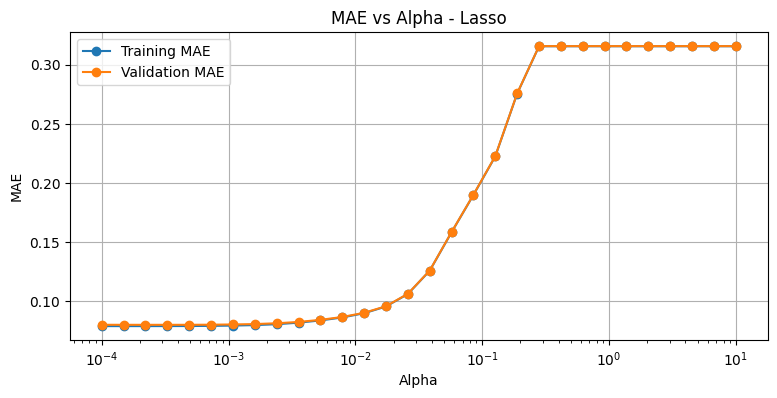

In [ ]:
# Plot train and test scores against alpha

plt.figure(figsize=(9, 4))

plt.plot(
    cv_results_lasso['param_alpha'],
    np.abs(cv_results_lasso['mean_train_score']),
    marker='o',
    label='Training MAE'
)

plt.plot(
    cv_results_lasso['param_alpha'],
    np.abs(cv_results_lasso['mean_test_score']),
    marker='o',
    label='Validation MAE'
)

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('MAE vs Alpha - Lasso')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Best alpha value

best_lasso_alpha = model_cv_lasso.best_params_['alpha']
print("Best Lasso alpha value:", best_lasso_alpha)

# Best score (negative MAE)
best_lasso_score = model_cv_lasso.best_score_
print("Best score (negative MAE):", best_lasso_score)
print("Best MAE:", abs(best_lasso_score))

Best Lasso alpha value: 0.000221221629107045
Best score (negative MAE): -0.07973038348059439
Best MAE: 0.07973038348059439


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [ ]:
# List of alphas to tune for Lasso regularization

best_alpha = model_cv_lasso.best_params_['alpha']

lower = best_alpha / 2
upper = best_alpha * 2

refined_alpha_list = np.linspace(lower, upper, 30)

print("Refined alpha range:", refined_alpha_list)

Refined alpha range: [0.00011061 0.00012205 0.0001335  0.00014494 0.00015638 0.00016782
 0.00017927 0.00019071 0.00020215 0.00021359 0.00022504 0.00023648
 0.00024792 0.00025936 0.00027081 0.00028225 0.00029369 0.00030513
 0.00031658 0.00032802 0.00033946 0.0003509  0.00036235 0.00037379
 0.00038523 0.00039667 0.00040812 0.00041956 0.000431   0.00044244]


In [ ]:
# Tuning Lasso hyperparameters

lasso = Lasso(max_iter=5000)

param_grid = {'alpha': refined_alpha_list}

model_cv_lasso = GridSearchCV(
    estimator=lasso,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5,
    return_train_score=True,
    verbose=5
)

model_cv_lasso.fit(X_train_scaled, y_train)


cv_results_lasso = pd.DataFrame(model_cv_lasso.cv_results_)
cv_results_lasso['param_alpha'] = cv_results_lasso['param_alpha'].astype(float)

cv_results_lasso.head()

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV 1/5] END alpha=0.0001106108145535225;, score=(train=-0.078, test=-0.080) total time=   0.5s
[CV 2/5] END alpha=0.0001106108145535225;, score=(train=-0.079, test=-0.080) total time=   0.6s
[CV 3/5] END alpha=0.0001106108145535225;, score=(train=-0.078, test=-0.081) total time=   0.6s
[CV 4/5] END alpha=0.0001106108145535225;, score=(train=-0.079, test=-0.080) total time=   0.6s
[CV 5/5] END alpha=0.0001106108145535225;, score=(train=-0.079, test=-0.079) total time=   0.5s
[CV 1/5] END alpha=0.00012205331261078346;, score=(train=-0.078, test=-0.080) total time=   0.5s
[CV 2/5] END alpha=0.00012205331261078346;, score=(train=-0.079, test=-0.080) total time=   0.5s
[CV 3/5] END alpha=0.00012205331261078346;, score=(train=-0.078, test=-0.081) total time=   0.6s
[CV 4/5] END alpha=0.00012205331261078346;, score=(train=-0.079, test=-0.080) total time=   0.4s
[CV 5/5] END alpha=0.00012205331261078346;, score=(train=-0.079, test=

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.544823,0.043620,0.004831,0.001046,0.000111,{'alpha': 0.0001106108145535225},-0.079921,-0.079999,-0.080557,-0.079792,-0.078536,-0.079761,0.000666,30,-0.078465,-0.078825,-0.078474,-0.078583,-0.078813,-0.078632,0.000158
1,0.481945,0.076130,0.003976,0.000032,0.000122,{'alpha': 0.00012205331261078346},-0.079928,-0.079981,-0.080548,-0.079794,-0.078523,-0.079755,0.000668,29,-0.078465,-0.078824,-0.078473,-0.078583,-0.078814,-0.078632,0.000158
2,0.421064,0.064681,0.003948,0.000016,0.000133,{'alpha': 0.0001334958106680444},-0.079936,-0.079966,-0.080538,-0.079799,-0.078511,-0.079750,0.000669,28,-0.078466,-0.078823,-0.078472,-0.078584,-0.078815,-0.078632,0.000158
3,0.376868,0.062041,0.003973,0.000034,0.000145,{'alpha': 0.00014493830872530536},-0.079943,-0.079953,-0.080529,-0.079801,-0.078499,-0.079745,0.000671,26,-0.078467,-0.078822,-0.078472,-0.078584,-0.078815,-0.078632,0.000158
4,0.474427,0.059077,0.005841,0.001818,0.000156,{'alpha': 0.00015638080678256628},-0.079950,-0.079942,-0.080521,-0.079802,-0.078488,-0.079740,0.000673,21,-0.078468,-0.078822,-0.078472,-0.078585,-0.078816,-0.078633,0.000158


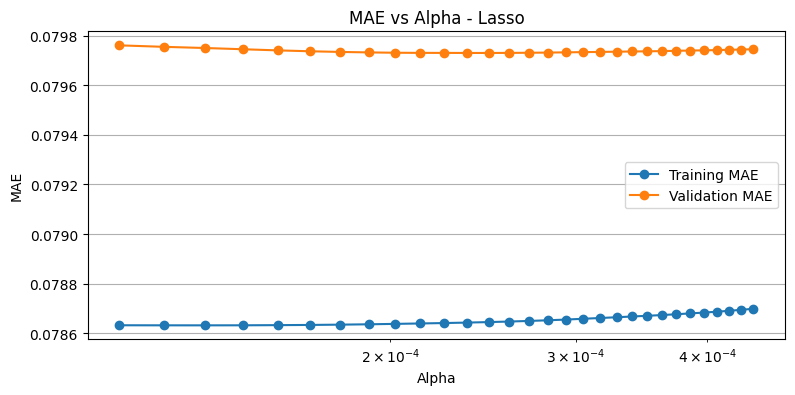

In [ ]:
# Plot train and test scores against alpha


plt.figure(figsize=(9, 4))

plt.plot(
    cv_results_lasso['param_alpha'],
    np.abs(cv_results_lasso['mean_train_score']),
    marker='o',
    label='Training MAE'
)

plt.plot(
    cv_results_lasso['param_alpha'],
    np.abs(cv_results_lasso['mean_test_score']),
    marker='o',
    label='Validation MAE'
)

plt.xscale('log')   # IMPORTANT
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('MAE vs Alpha - Lasso')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Best alpha value

best_lasso_alpha = model_cv_lasso.best_params_['alpha']
print("Best alpha value:", best_lasso_alpha)

# Best score (negative MAE)
best_lasso_score = model_cv_lasso.best_score_
print("Best score (negative MAE):", best_lasso_score)
print("Best MAE:", abs(best_lasso_score))

Best alpha value: 0.00024792079124065383
Best score (negative MAE): -0.07973010537575842
Best MAE: 0.07973010537575842


In [ ]:
# Set best alpha for Lasso regression

best_lasso_model = Lasso(alpha=best_lasso_alpha, max_iter=5000)


# Fit the Lasso model on scaled training data
best_lasso_model.fit(X_train_scaled, y_train)

# Get the coefficients of the fitted model
lasso_coefficients = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': best_lasso_model.coef_
}).sort_values(by='Coefficient', ascending=False)

In [ ]:
# Check the coefficients for each feature

print("\nLasso Coefficients:")
print(lasso_coefficients)


Lasso Coefficients:
                         Feature  Coefficient
4                          hp_kW     0.100334
82          num_comfort_features     0.040158
86            make_model_Audi A3     0.037113
92     make_model_Renault Espace     0.036105
107  Gearing_Type_Semi-automatic     0.018266
..                           ...          ...
87         make_model_Opel Astra    -0.079753
2                            age    -0.090951
0                             km    -0.092395
90       make_model_Renault Clio    -0.120280
88         make_model_Opel Corsa    -0.150876

[110 rows x 2 columns]


In [ ]:
# Evaluate the Lasso model on the test data

y_pred_log_lasso = best_lasso_model.predict(X_test_scaled)

mae_log = mean_absolute_error(y_test, y_pred_log_lasso)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log_lasso))
r2_log = r2_score(y_test, y_pred_log_lasso)

print("\nEvaluation on log scale:")
print("MAE:", mae_log)
print("RMSE:", rmse_log)
print("R2:", r2_log)


y_pred_lasso = np.expm1(y_pred_log_lasso)
y_actual = np.expm1(y_test)


mae_original = mean_absolute_error(y_actual, y_pred_lasso)
rmse_original = np.sqrt(mean_squared_error(y_actual, y_pred_lasso))
r2_original = r2_score(y_actual, y_pred_lasso)

print("\nEvaluation on original scale:")
print("MAE:", mae_original)
print("RMSE:", rmse_original)
print("R2:", r2_original)




Evaluation on log scale:
MAE: 0.07874657384832065
RMSE: 0.1066713177522432
R2: 0.9287710104610185

Evaluation on original scale:
MAE: 1480.04693070379
RMSE: 2336.9550437471894
R2: 0.9019295226930009


### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [ ]:
# Compare metrics for each model

# Store models in dictionary
models = {
    'Linear Regression': lr_model,
    'Ridge Regression': best_ridge_model,
    'Lasso Regression': best_lasso_model
}

results = []

for model_name, model in models.items():
    # Predict on log scale
    y_pred_log = model.predict(X_test_scaled)

    # Metrics on log scale
    mae_log = mean_absolute_error(y_test, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    r2_price_log = r2_score(y_test, y_pred_log)

    # Convert back to original scale
    y_pred = np.expm1(y_pred_log)
    y_actual = np.expm1(y_test)

    # Metrics on original scale
    mae_original = mean_absolute_error(y_actual, y_pred)
    rmse_original = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2_price_original = r2_score(y_actual, y_pred)

    # Store results
    results.append({
        'Model': model_name,
        'MAE_log': mae_log,
        'RMSE_log': rmse_log,
        'r2_price_log': r2_price_log,
        'MAE_original': mae_original,
        'RMSE_original': rmse_original,
        'r2_price_original': r2_price_original
    })

# Create results dataframe
results_df = pd.DataFrame(results)

# Sort by lowest RMSE on original scale
results_df = results_df.sort_values(by='RMSE_original')

display(results_df)

,Model,MAE_log,RMSE_log,r2_price_log,MAE_original,RMSE_original,r2_price_original
0,Linear Regression,0.078566,0.106433,0.929090,1476.332783,2329.269833,0.902573
1,Ridge Regression,0.078611,0.106502,0.928997,1476.977625,2330.790150,0.902446
2,Lasso Regression,0.078747,0.106671,0.928771,1480.046931,2336.955044,0.901930


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

In [ ]:
# Compare highest coefficients and coefficients of eliminated features

#Extract co efficients for all models -
# Linear Regression coefficients
lr_coef = pd.Series(lr_model.coef_, index=X_train_scaled.columns)

# Ridge coefficients
ridge_coef = pd.Series(best_ridge_model.coef_, index=X_train_scaled.columns)

# Lasso coefficients
lasso_coef = pd.Series(best_lasso_model.coef_, index=X_train_scaled.columns)

coef_df = pd.DataFrame({
    'Linear': lr_coef,
    'Ridge': ridge_coef,
    'Lasso': lasso_coef
})

coef_df.head()

#Compare magnitude of coefficients
coef_df_abs = coef_df.abs()
coef_df_abs.head()

#Largest Coefficients
top_features = coef_df_abs.mean(axis=1).sort_values(ascending=False).head(15).index
top_coef_df = coef_df.loc[top_features]
print(top_coef_df)

                               Linear     Ridge     Lasso
make_model_Opel Corsa       -0.151827 -0.149719 -0.150876
make_model_Renault Clio     -0.122021 -0.120086 -0.120280
hp_kW                        0.102458  0.101665  0.100334
km                          -0.092723 -0.092579 -0.092395
age                         -0.090501 -0.090346 -0.090951
make_model_Opel Astra       -0.081075 -0.079072 -0.079753
num_comfort_features         0.079967  0.051707  0.040158
Gearing_Type_Manual         -0.056762 -0.056498 -0.057333
Type_Used                   -0.040663 -0.040036 -0.038057
make_model_Audi A3           0.037476  0.037995  0.037113
make_model_Renault Espace    0.034810  0.036167  0.036105
make_model_Opel Insignia    -0.025981 -0.024340 -0.024459
Type_Employee's car         -0.023950 -0.023563 -0.022299
Gearing_Type_Semi-automatic  0.018410  0.018418  0.018266
Type_Pre-registered         -0.018924 -0.018464 -0.017081


<Figure size 1400x600 with 0 Axes>

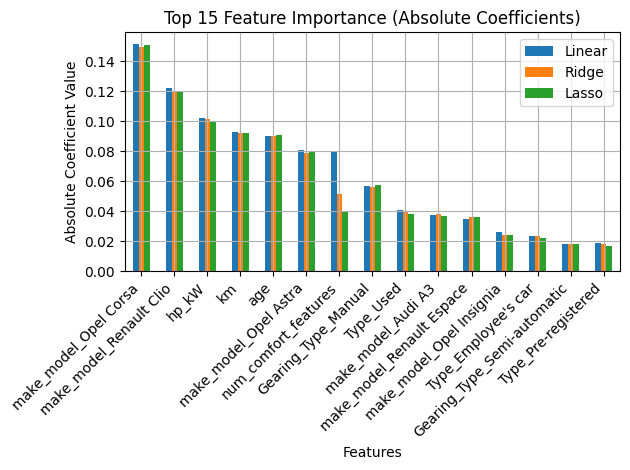

In [ ]:

top_coef_abs = top_coef_df.abs()

plt.figure(figsize=(14,6))

top_coef_abs.plot(kind='bar')

plt.title("Top 15 Feature Importance (Absolute Coefficients)")
plt.xlabel("Features")
plt.ylabel("Absolute Coefficient Value")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
#Identify the features/Coefficients dropped by lasso

lasso_dropped = coef_df[coef_df['Lasso'] == 0].index

print("Number of features dropped by Lasso:", len(lasso_dropped))
print("Dropped features:\n", lasso_dropped)


Number of features dropped by Lasso: 11
Dropped features:
 Index(['Previous_Owners', 'Electronic stability control',
       'Traffic sign recognition', 'Light sensor', 'Tinted windows',
       'Hands-free equipment', 'Sport seats', 'num_safety_features',
       'num_entertainment_features', 'make_model_Audi A2',
       'body_type_Station wagon'],
      dtype='object')


In [ ]:
selected_features = coef_df[coef_df['Lasso'] != 0]
print("Selected features:", len(selected_features))

Selected features: 99


In [ ]:
coef_df = pd.DataFrame({
    'Linear': lr_coef,
    'Ridge': ridge_coef,
    'Lasso': lasso_coef
})

# Identify eliminated features (Lasso = 0)
lasso_dropped_df = coef_df[coef_df['Lasso'] == 0].copy()

# Add absolute values for comparison
lasso_dropped_df['Abs_Linear'] = lasso_dropped_df['Linear'].abs()
lasso_dropped_df['Abs_Ridge'] = lasso_dropped_df['Ridge'].abs()

# Sort by importance in Linear/Ridge
lasso_dropped_df = lasso_dropped_df.sort_values(
    by=['Abs_Linear', 'Abs_Ridge'],
    ascending=False
)

# Display top eliminated features
print("\nEliminated features with their coefficients:")
display(lasso_dropped_df.head(15))



Eliminated features with their coefficients:


,Linear,Ridge,Lasso,Abs_Linear,Abs_Ridge
num_entertainment_features,1.275720e-02,0.001853,-0.0,1.275720e-02,0.001853
num_safety_features,6.660984e-03,0.004032,-0.0,6.660984e-03,0.004032
Light sensor,-3.439467e-03,-0.001141,-0.0,3.439467e-03,0.001141
Hands-free equipment,-2.581170e-03,0.000026,0.0,2.581170e-03,0.000026
Tinted windows,-2.154111e-03,-0.000759,-0.0,2.154111e-03,0.000759
body_type_Station wagon,9.562013e-04,0.000730,0.0,9.562013e-04,0.000730
Electronic stability control,-8.261549e-04,-0.000450,-0.0,8.261549e-04,0.000450
Sport seats,-7.633030e-04,-0.000729,-0.0,7.633030e-04,0.000729
Traffic sign recognition,-7.502800e-04,-0.000561,-0.0,7.502800e-04,0.000561
Previous_Owners,5.551115e-17,0.000000,0.0,5.551115e-17,0.000000


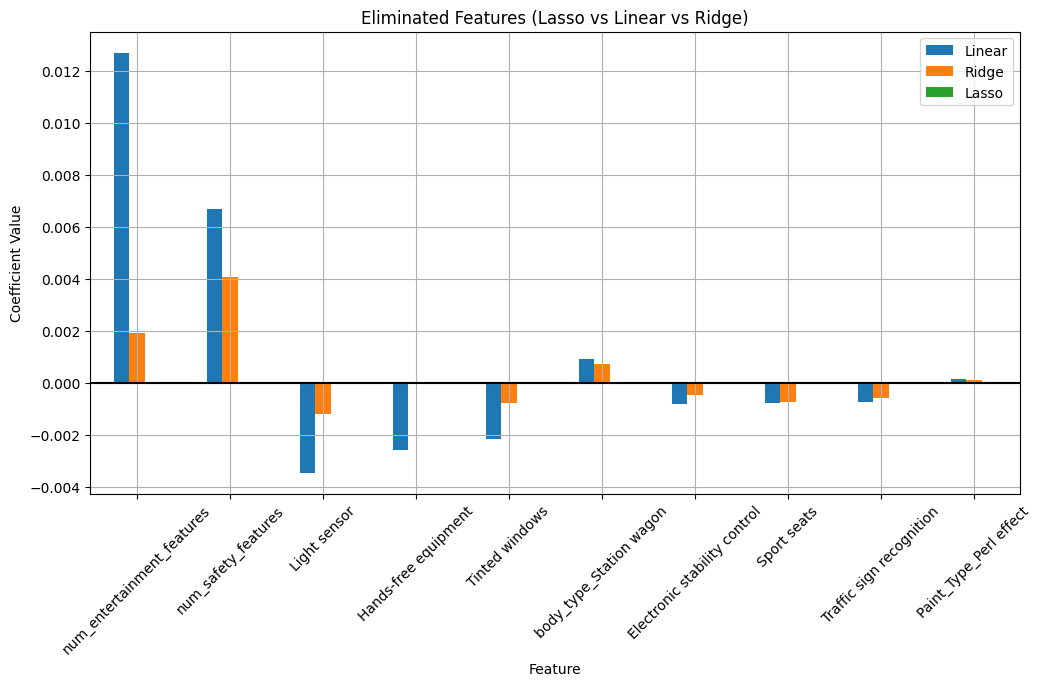

In [ ]:

top_dropped = lasso_dropped_df.head(10)

top_dropped[['Linear', 'Ridge', 'Lasso']].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Eliminated Features (Lasso vs Linear vs Ridge)")
plt.ylabel("Coefficient Value")
plt.xlabel("Feature")
plt.xticks(rotation=45)
plt.axhline(0, color='black')
plt.grid(True)
plt.show()


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

Ridge and Lasso did not significantly improve performance over Linear Regression.
Metrics across all 3 models are almost identical
Regularization improved model stability and simplicity, NOT predictive accuracy
There is no significant change as the Data is sufficient and is well-preprocessed, no severe multicollinearity, Linear model is already strong.
Dataset quality and size are adequate
hp_kW (engine power), Gears,  Weight_kg have high positive coefficient value and have more correlation with target variable
age,km have high negative coefficients and is inversely proportional to target price
Inspection_new, Previous_owners have no effect on target price
Irregularities in data were handled
           by applying log transformation to target Price
           by capping the outliers of numeric predictors
           grouping the rare categories in Paint_type, body_type and Fuel
Feature importance Summary
            High influence features – hp_kw, Gears, Weight, Age, KM
            Moderate influence Features – Displacement, Fuel Consumption
            Low influence Features – Inspection new, Previous_Owners
Linear Regression performed best, Ridge regression had identical performance and lasso had a slightly lower performance due to removal of some coefficients. Performance metrics MAE, RMSE, R2 Scores were used to determine the performance

Model gives the price range and not the exact price of the car as exact price depends on Buyer – Seller agreement
Prediction error varies between 1500-2300 based on MAE and RMSE Values got by the model.
